# Vision — Clustering Gambar (tanpa label)
**Kapan dipakai:** ada tumpukan gambar tanpa label dan soal meminta "kelompokkan" / "temukan
tema" / "berapa jenis gambar yang ada".

**Langkah:** embedding CLIP → UMAP (peta ringkas) → KMeans (jumlah klaster ditentukan) atau
HDBSCAN (jumlah klaster otomatis, titik aneh = -1) → lihat contoh gambar tiap klaster.
Alternatif reduksi: PCA (baris `#`). Skor: NMI/ARI terhadap label demo (jika ada label).

**Data demo:** CIFAR-10 kecil (10 kelas). Label hanya dipakai untuk mengukur, bukan melatih.

In [1]:
import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import umap
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from transformers import CLIPModel, CLIPProcessor

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/classification/cifar10_small"  # GANTI
IMAGES_CSV = f"{DATA_FOLDER}/train.csv"
CLIP_FOLDER = "../../pretrained/clip_b32"

PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
LABEL_COL = "label"   # hanya ada di data demo, untuk mengukur
N_CLUSTERS = 10       # untuk KMeans. Tidak tahu? lihat silhouette di bawah
MIN_CLUSTER_SIZE = 40  # HDBSCAN: klaster paling kecil yang dianggap sah
EXAMPLES_PER_CLUSTER = 8
BATCH_SIZE = 64
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
images = pd.read_csv(IMAGES_CSV)
image_paths = list(images[PATH_COL])
print(images.shape)
images.head()

(4000, 2)


,path,label
0,train/airplane/0000.png,airplane
1,train/airplane/0001.png,airplane
2,train/airplane/0002.png,airplane
3,train/airplane/0003.png,airplane
4,train/airplane/0004.png,airplane


## Embedding CLIP (beku)

In [4]:
clip = CLIPModel.from_pretrained(CLIP_FOLDER, local_files_only=True)
clip = clip.to(DEVICE)
clip.eval()
processor = CLIPProcessor.from_pretrained(CLIP_FOLDER, local_files_only=True)

batches = []
for start in range(0, len(image_paths), BATCH_SIZE):
    batch_images = []
    for path in image_paths[start:start + BATCH_SIZE]:
        batch_images.append(Image.open(f"{DATA_FOLDER}/{path}").convert("RGB"))
    encoded = processor(images=batch_images, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        output = clip.get_image_features(**encoded)
    batches.append(output.pooler_output.cpu().numpy())
embedding = np.concatenate(batches)
embedding = embedding / np.linalg.norm(embedding, axis=1, keepdims=True)   # panjang 1
print(embedding.shape)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

(4000, 512)


## Reduksi dimensi: UMAP
Klaster dicari di ruang 10 dimensi, peta 2D hanya untuk digambar.
Pilih SATU blok: UMAP (aktif) atau PCA (lebih cepat, hasil biasanya lebih kasar).

In [5]:
umap_10d = umap.UMAP(n_components=10, n_neighbors=15, min_dist=0.0, metric="cosine",
                     random_state=SEED)
X_10d = umap_10d.fit_transform(embedding)
umap_2d = umap.UMAP(n_components=2, n_neighbors=15, metric="cosine", random_state=SEED)
X_2d = umap_2d.fit_transform(embedding)

# X_10d = PCA(n_components=10, random_state=SEED).fit_transform(embedding)
# X_2d = PCA(n_components=2, random_state=SEED).fit_transform(embedding)

Z:\GEMASTIK-DATABASE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Z:\GEMASTIK-DATABASE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Berapa klaster? Silhouette untuk beberapa jumlah
Silhouette makin dekat 1 makin rapi (tanpa label). Pilih jumlah dengan nilai tinggi, lalu
isi `N_CLUSTERS` di Konfigurasi.

In [6]:
for n_clusters in [5, 8, 10, 12, 15]:
    trial = KMeans(n_clusters=n_clusters, n_init=5, random_state=SEED)
    trial_clusters = trial.fit_predict(X_10d)
    print(n_clusters, "klaster -> silhouette", round(silhouette_score(X_10d, trial_clusters), 3))

5 klaster -> silhouette 0.611


8 klaster -> silhouette 0.721


10 klaster -> silhouette 0.668


12 klaster -> silhouette 0.64


15 klaster -> silhouette 0.584


## Klaster: KMeans dan HDBSCAN

In [7]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
kmeans_clusters = kmeans.fit_predict(X_10d)
print("silhouette KMeans:", round(silhouette_score(X_10d, kmeans_clusters), 3))

finder = hdbscan.HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE)
hdbscan_clusters = finder.fit_predict(X_10d)      # -1 = tidak masuk klaster mana pun
n_hdbscan = len(set(hdbscan_clusters)) - 1
print("klaster HDBSCAN:", n_hdbscan, "| titik -1:", (hdbscan_clusters == -1).sum())

silhouette KMeans: 0.668
klaster HDBSCAN: 5 | titik -1: 0


## Peta 2D

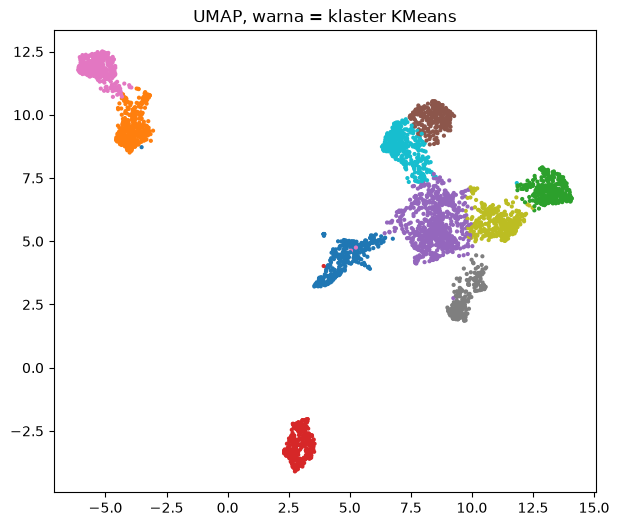

In [8]:
plt.figure(figsize=(7, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans_clusters, cmap="tab10", s=4)
plt.title("UMAP, warna = klaster KMeans")
plt.savefig("peta_umap.png", dpi=120)
plt.show()

## Contoh gambar tiap klaster
Gambar paling dekat ke pusat klaster = paling mewakili. Lihat contohnya, lalu beri nama
klaster itu sendiri.

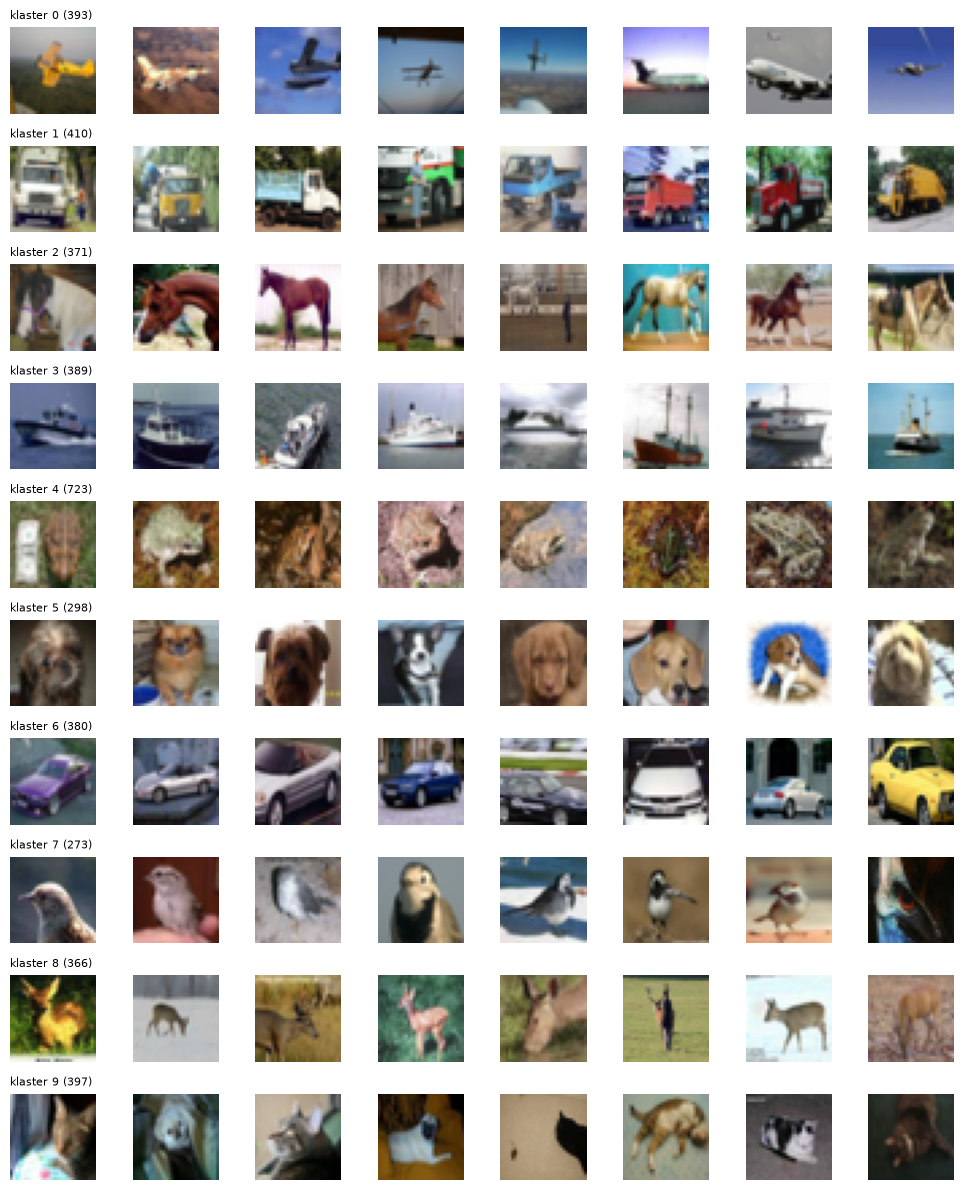

In [9]:
fig, axes = plt.subplots(N_CLUSTERS, EXAMPLES_PER_CLUSTER, figsize=(10, 12))
for cluster in range(N_CLUSTERS):
    members = np.where(kmeans_clusters == cluster)[0]
    distances = np.linalg.norm(X_10d[members] - kmeans.cluster_centers_[cluster], axis=1)
    chosen = members[np.argsort(distances)[:EXAMPLES_PER_CLUSTER]]
    for column in range(EXAMPLES_PER_CLUSTER):
        axes[cluster, column].axis("off")
        if column < len(chosen):
            path = image_paths[chosen[column]]
            axes[cluster, column].imshow(Image.open(f"{DATA_FOLDER}/{path}"))
    title = "klaster " + str(cluster) + " (" + str(len(members)) + ")"
    axes[cluster, 0].set_title(title, fontsize=8, loc="left")
plt.tight_layout()
plt.savefig("contoh_per_klaster.png", dpi=100)
plt.show()

## Hasil
Tabel klaster per gambar (nama kolom diganti sesuai format soal).

In [10]:
result = pd.DataFrame()
result["path"] = images[PATH_COL]
result["klaster_kmeans"] = kmeans_clusters
result["klaster_hdbscan"] = hdbscan_clusters
result.to_csv("klaster.csv", index=False)
result.head()

,path,klaster_kmeans,klaster_hdbscan
0,train/airplane/0000.png,0,2
1,train/airplane/0001.png,0,2
2,train/airplane/0002.png,0,2
3,train/airplane/0003.png,4,5
4,train/airplane/0004.png,0,2


## Skor terhadap label demo (HAPUS saat lomba bila tidak ada label)
NMI/ARI: 1 = klaster sama persis dengan kelas asli, 0 = acak.

In [11]:
true_labels = images[LABEL_COL]
print("KMeans  NMI:", round(normalized_mutual_info_score(true_labels, kmeans_clusters), 3),
      "ARI:", round(adjusted_rand_score(true_labels, kmeans_clusters), 3))
print("HDBSCAN NMI:", round(normalized_mutual_info_score(true_labels, hdbscan_clusters), 3),
      "ARI:", round(adjusted_rand_score(true_labels, hdbscan_clusters), 3))
print(pd.crosstab(true_labels, kmeans_clusters))   # komposisi kelas asli tiap klaster

KMeans  NMI: 0.773 ARI: 0.693
HDBSCAN NMI: 0.685 ARI: 0.391
col_0         0    1    2    3    4    5    6    7    8    9
label                                                       
airplane    369    3    0    4   23    0    1    0    0    0
automobile    1   24    0    0    4    0  371    0    0    0
bird         14    0    1    1   89    1    0  267   19    8
cat           1    0    0    0   79    7    0    4    7  302
deer          0    0   10    0   81    2    0    0  305    2
dog           0    0    6    0   25  288    0    0    6   75
frog          1    0    1    0  385    0    0    2    4    7
horse         0    0  353    0   21    0    0    0   24    2
ship          6    1    0  384    6    0    2    0    0    1
truck         1  382    0    0   10    0    6    0    1    0
